# Whisper to Voice: system walkthrough

MAI522 Speech Processing and Recognition, group mini project.

This notebook runs the whole system step by step on one clip. Every step has a short explanation, then the project's own `src` function is called and the result is shown as a plot or as audio. Nothing here reimplements the DSP; only the plotting helpers are local.

Contents: 0 Problem and idea, 1 Load audio, 2 Framing, 3 Frame classification, 4 LPC, 5 Source (pitch and excitation), 6 Synthesis and output stage, 7 Ablation variants, 8 Live path, 9 Evaluation, 10 Summary.

## 0. Problem and idea

**Whispered speech has no vocal-fold vibration.** In normal speech the vocal folds open and close about 100 to 250 times a second. This produces a periodic *source* (the buzz, with pitch). In a whisper the folds stay apart and the source is only turbulent air noise. The *shape of the mouth and throat* (the vocal tract) still filters the sound, so the vowels and consonants are still there, but there is no pitch.

**Source-filter model.** Speech = source passed through a filter:

- source `e[n]`: periodic glottal pulses (voiced) or noise (whisper, fricatives)
- filter `H(z) = G / A(z)`, the vocal tract, modelled as an all-pole filter of order 12 (LPC)

Our idea: keep the filter that the whisper already contains, and swap the noise source for a synthetic voiced source that we control (pitch contour, pulse shape).

    whisper -> frames -> classify (silence / consonant / vowel)
                      -> LPC per frame (vocal tract filter A(z), gain G)
    labels + energy   -> f0 contour -> excitation (pulses / noise / zeros)
    excitation -> G / A(z) -> lip radiation + de-emphasis + DC blocker + RMS match -> peak protect -> voiced speech

Format throughout: 16 kHz mono float32, frame 320 samples (20 ms), hop 160 samples (10 ms).

In [1]:
import sys, os, time
from pathlib import Path

# Find the repo root (the folder containing src/), whatever the working directory is
root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)

import numpy as np
import scipy.signal
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown, Image

from src import framing, detect, lpc, pitch, synth, live, evaluate
from tests.fixtures import write_fixture

FS, FRAME, HOP = 16000, 320, 160
plt.rcParams.update({"figure.figsize": (9, 3), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

def play(x, label, max_s=8.0):
    # Audio player for the first max_s seconds (keeps the notebook file small)
    x = np.asarray(x, dtype=np.float32)[: int(max_s * FS)]
    print(f"{label} ({len(x) / FS:.1f} s)")
    display(Audio(x, rate=FS))

def spec_db(x, n_fft=512, hop=HOP):
    f, t, Z = scipy.signal.stft(x, fs=FS, window="hann", nperseg=n_fft, noverlap=n_fft - hop, boundary=None, padded=False)
    return f, t, 20 * np.log10(np.abs(Z) + 1e-8)

def show_spec(ax, x, title, vmax=None, fmax=8000, dyn=70):
    f, t, S = spec_db(x)
    vmax = S.max() if vmax is None else vmax
    ax.imshow(S, origin="lower", aspect="auto", extent=[t[0], t[-1], f[0], f[-1]], vmin=vmax - dyn, vmax=vmax, cmap="magma")
    ax.set_ylim(0, fmax); ax.set_title(title); ax.set_xlabel("time (s)"); ax.set_ylabel("Hz"); ax.grid(False)
    return S.max()

print("repo root:", root)

repo root: D:\whisper_to_voice_repo\whisper_to_voice


## 1. Load audio

`load_audio` reads the file, forces mono, resamples to 16 kHz and removes DC with a one-pole high-pass (`dc_block`). We use the shared test recording `data/raw/shared_test.wav` if it exists. If not (for example on a fresh clone), we generate the synthetic pseudo-whisper used by the test suite: formant-filtered noise shaped like the vowels a, i, u with an "s" fricative, and silence at the start. The notebook works with either; the cell prints which one is used.

Clip used: SYNTHETIC pseudo-whisper from tests/fixtures.py write_fixture (no real recording found)
41120 samples, fs = 16000 Hz, duration 2.57 s, peak 0.406


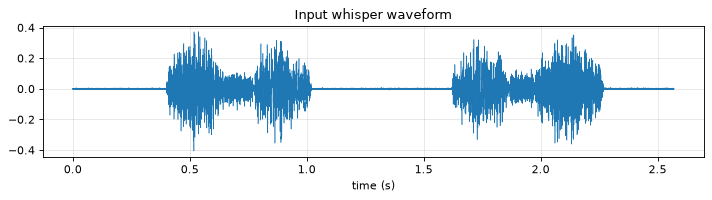

Input whisper (2.6 s)


In [2]:
real = root / "data" / "raw" / "shared_test.wav"
if real.exists():
    wav_path = real
    CLIP = "real recording: data/raw/shared_test.wav"
else:
    wav_path = root / "results" / "walkthrough_fixture.wav"
    wav_path.parent.mkdir(exist_ok=True)
    write_fixture(str(wav_path), voiced=False)
    CLIP = "SYNTHETIC pseudo-whisper from tests/fixtures.py write_fixture (no real recording found)"
print("Clip used:", CLIP)

x, fs = framing.load_audio(str(wav_path))
print(f"{len(x)} samples, fs = {fs} Hz, duration {len(x) / fs:.2f} s, peak {np.abs(x).max():.3f}")

t = np.arange(len(x)) / fs
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(t, x, lw=0.5); ax.set_xlabel("time (s)"); ax.set_title("Input whisper waveform"); plt.tight_layout(); plt.show()
play(x, "Input whisper")

## 2. Framing (Module A)

Speech is only roughly stationary over about 20 ms, so we cut the signal into overlapping **frames** of 320 samples with a hop of 160 samples (50 percent overlap). `frame_signal` does this without windowing; the window (Hamming) is applied later inside the LPC step.

Per frame we compute simple features:

- **RMS energy** `sqrt(mean(x^2))`: loudness. Used for silence detection, loudness matching at the output, and stress in the pitch contour.
- **Zero-crossing rate (ZCR)**: fraction of adjacent samples that change sign. Noise-like sounds (fricatives such as "s") cross zero very often; low-pitched vowels rarely.
- **Voicing strength**: peak of the normalised autocorrelation in the pitch lag range (40 to 228 samples = 400 to 70 Hz). Near 1 for a periodic signal, about 0.2 for white noise. A whisper scores clearly lower than voiced speech but not zero, because narrow formant resonances make filtered noise partly predictable (synthetic clip: about 0.6, against about 1.0 for the same clip voiced). It is a diagnostic only; `classify_frames` uses RMS and ZCR.

frames: (256, 320)  (n_frames, frame_len)


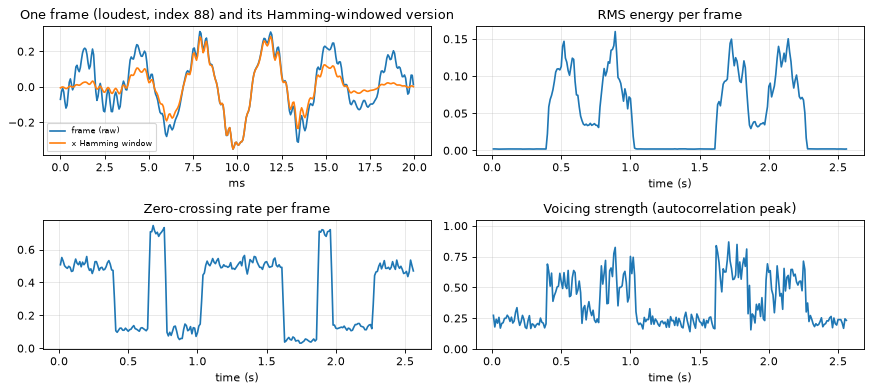

mean voicing strength over loud frames: 0.57


In [3]:
frames = framing.frame_signal(x)
energy = framing.frame_energy(frames)
zcr = framing.frame_zcr(frames)
vs = detect.voicing_strength(frames)
tf = (np.arange(len(frames)) * HOP + FRAME / 2) / FS
print("frames:", frames.shape, " (n_frames, frame_len)")

fig, axs = plt.subplots(2, 2, figsize=(11, 5))
k = int(np.argmax(energy))
axs[0, 0].plot(np.arange(FRAME) / FS * 1000, frames[k], label="frame (raw)")
axs[0, 0].plot(np.arange(FRAME) / FS * 1000, frames[k] * np.hamming(FRAME), label="x Hamming window")
axs[0, 0].set_title(f"One frame (loudest, index {k}) and its Hamming-windowed version"); axs[0, 0].set_xlabel("ms"); axs[0, 0].legend(fontsize=7)
axs[0, 1].plot(tf, energy); axs[0, 1].set_title("RMS energy per frame"); axs[0, 1].set_xlabel("time (s)")
axs[1, 0].plot(tf, zcr); axs[1, 0].set_title("Zero-crossing rate per frame"); axs[1, 0].set_xlabel("time (s)")
axs[1, 1].plot(tf, vs); axs[1, 1].set_ylim(0, 1.05); axs[1, 1].set_title("Voicing strength (autocorrelation peak)"); axs[1, 1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()
print(f"mean voicing strength over loud frames: {vs[energy > 3 * np.median(energy)].mean():.2f}")

## 3. Frame classification

`classify_frames` gives each 10 ms hop one of three labels:

| label | meaning | later used as |
|---|---|---|
| 0 | silence | excitation is exactly zero |
| 1 | consonant (noisy, high ZCR) | white noise excitation, no pitch |
| 2 | vowel-like (loud, low ZCR) | glottal pulse train with pitch |

How the thresholds are chosen (`calibrate_thresholds`):

- **Silence threshold** = 3 x the median RMS of the first 0.3 s of the clip. That is why the speaker must stay silent for the first 0.3 s: this is the noise-floor calibration. If the clip starts with speech, the noise floor falls back to the 10th percentile of all energies.
- **ZCR threshold** = 70th percentile of the ZCR of the non-silent frames. Frames above it are noisy consonants, below it vowel-like.
- **Hangover** (5 frames): after speech, the label is held for 50 ms so quiet word endings are not cut off. Finally a 3-frame median filter removes isolated label flips.

silence threshold (RMS) = 0.00583   ZCR threshold = 0.137
frames per label: silence 117  consonant 49  vowel-like 90


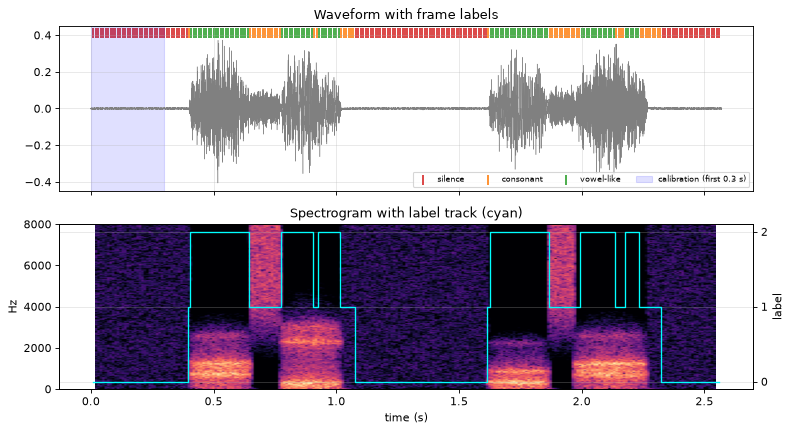

In [4]:
labels, zcr_thr, sil_thr = detect.classify_frames(frames, energy, return_thresholds=True)
print(f"silence threshold (RMS) = {sil_thr:.5f}   ZCR threshold = {zcr_thr:.3f}")
print("frames per label: silence", int((labels == 0).sum()), " consonant", int((labels == 1).sum()), " vowel-like", int((labels == 2).sum()))

COL = {0: "tab:red", 1: "tab:orange", 2: "tab:green"}
NAME = {0: "silence", 1: "consonant", 2: "vowel-like"}

fig, axs = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axs[0].plot(t, x, lw=0.4, color="gray")
for lbl in (0, 1, 2):
    m = labels == lbl
    axs[0].scatter(tf[m], np.full(m.sum(), x.max() * 1.1), c=COL[lbl], marker="|", s=80, label=NAME[lbl])
axs[0].axvspan(0, 0.3, color="blue", alpha=0.12, label="calibration (first 0.3 s)")
axs[0].legend(ncol=4, fontsize=7, loc="lower right"); axs[0].set_title("Waveform with frame labels")
f_, t_, S = spec_db(x)
axs[1].imshow(S, origin="lower", aspect="auto", extent=[t_[0], t_[-1], 0, 8000], vmin=S.max() - 70, vmax=S.max(), cmap="magma")
axs[1].set_ylim(0, 8000); axs[1].grid(False); axs[1].set_ylabel("Hz"); axs[1].set_xlabel("time (s)")
ax2 = axs[1].twinx(); ax2.step(tf, labels, where="mid", color="cyan", lw=1.2); ax2.set_yticks([0, 1, 2]); ax2.set_ylabel("label")
axs[1].set_title("Spectrogram with label track (cyan)")
plt.tight_layout(); plt.show()

## 4. LPC: the vocal tract filter (Module B)

**All-pole model.** Linear prediction says each sample is approximately a weighted sum of the previous `p` samples:

    x_hat[n] = - sum_{k=1..p} a[k] x[n-k]        error e[n] = x[n] - x_hat[n]

so the error is `e = A(z) x` with `A(z) = 1 + a[1] z^-1 + ... + a[p] z^-p`. Inverting this, the signal is the error (our excitation) passed through the all-pole filter `H(z) = G / A(z)`. The poles of `1/A(z)` sit near the unit circle at the vocal tract resonances (formants), so `|H|` is a smooth envelope over the harmonic fine structure.

Steps inside `lpc_frame` (order 12):

1. **Pre-emphasis** `y[n] = x[n] - 0.97 x[n-1]` flattens the speech spectrum tilt so the fit is not dominated by low frequencies.
2. **Hamming window** reduces edge effects.
3. **Autocorrelation** `r[k] = sum x[n] x[n+k]`, `k = 0..p`.
4. **Levinson-Durbin** solves the normal equations `R a = -r` in `O(p^2)` instead of `O(p^3)`. At step `i` it computes a reflection coefficient `k_i = -(r[i] + sum a[j] r[i-j]) / err`, updates `a`, and shrinks the error `err *= (1 - k_i^2)`. The filter is stable when every `|k_i| < 1`.
5. **Gain** `G = sqrt(err / sum(w^2))`, so unit-RMS excitation through `G / A(z)` has about the RMS of the pre-emphasised frame (`err` is the residual energy of the windowed frame, `sum(w^2)` the window energy). The output stage later matches the loudness to the input anyway.

Below, the five steps are called one by one on the loudest vowel-like frame.

Analysing frame 88 (t = 0.89 s, label 2)
autocorrelation r[0..4]: [ 0.1365  0.0995  0.0244 -0.0195  0.0016]
a (Levinson): [ 1.    -2.219  2.506 -1.284 -0.293  0.507 -0.131 -0.246  0.075  0.07
  0.034  0.003  0.051]
lpc_frame gives the same a: True   gain G = 0.00451


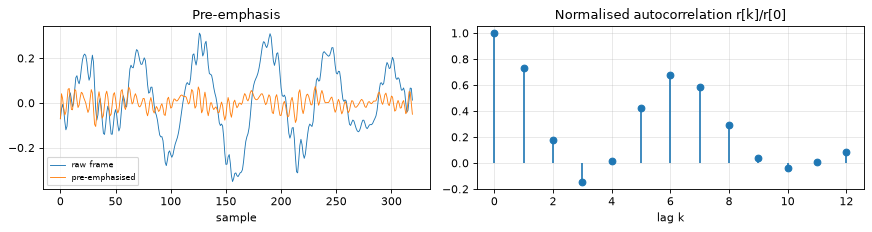

In [5]:
vowel_idx = np.flatnonzero(labels == 2)
idx = int(vowel_idx[np.argmax(energy[vowel_idx])]) if vowel_idx.size else int(np.argmax(energy))
fr = frames[idx]
print(f"Analysing frame {idx} (t = {tf[idx]:.2f} s, label {labels[idx]})")

pre = lpc.preemphasis(fr)
win = pre * np.hamming(FRAME)
r = lpc.autocorr(win, 12)
a, err = lpc.levinson(r, 12)
a_full, g = lpc.lpc_frame(fr, order=12)
print("autocorrelation r[0..4]:", np.round(r[:5], 4))
print("a (Levinson):", np.round(a, 3))
print("lpc_frame gives the same a:", np.allclose(a, a_full, atol=1e-6), "  gain G =", round(g, 5))

fig, axs = plt.subplots(1, 2, figsize=(11, 3))
axs[0].plot(fr, lw=0.8, label="raw frame"); axs[0].plot(pre, lw=0.8, label="pre-emphasised"); axs[0].legend(fontsize=7)
axs[0].set_title("Pre-emphasis"); axs[0].set_xlabel("sample")
axs[1].stem(np.arange(13), r / r[0], basefmt=" "); axs[1].set_title("Normalised autocorrelation r[k]/r[0]"); axs[1].set_xlabel("lag k")
plt.tight_layout(); plt.show()

**Spectrum vs LPC envelope.** The FFT of the windowed frame (blue) shows every detail of the frame. The LPC envelope (red, `lpc_envelope`) is the smooth curve that follows the formant peaks. The envelope level is matched to the FFT by mean dB for display. `envelope_lsd` quantifies the mismatch in dB.

**Residual and prediction gain.** Running the frame through `A(z)` (`residual`) removes the formant structure. The residual is much smaller than the frame; the ratio of energies is the `prediction_gain_db`. It is also roughly what we throw away and replace with our own source.

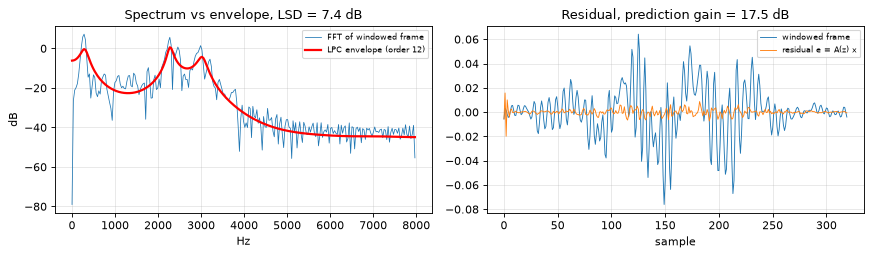

In [6]:
n_fft = 512
spec = 20 * np.log10(np.abs(np.fft.rfft(win, n_fft)) + 1e-12)
w, env = lpc.lpc_envelope(a, 1.0, n_fft)
env_m = env + (spec.mean() - env.mean())
e_res = lpc.residual(win, a)
pg = lpc.prediction_gain_db(win, a)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.3))
axs[0].plot(w, spec, lw=0.7, label="FFT of windowed frame"); axs[0].plot(w, env_m, "r", lw=2, label="LPC envelope (order 12)")
axs[0].set_xlabel("Hz"); axs[0].set_ylabel("dB"); axs[0].legend(fontsize=7)
axs[0].set_title(f"Spectrum vs envelope, LSD = {lpc.envelope_lsd(fr, 12):.1f} dB")
axs[1].plot(win, lw=0.8, label="windowed frame"); axs[1].plot(e_res, lw=0.8, label="residual e = A(z) x")
axs[1].set_title(f"Residual, prediction gain = {pg:.1f} dB"); axs[1].set_xlabel("sample"); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Poles on the unit circle.** The roots of `A(z)` are the poles of the synthesis filter. A pole at radius `r` and angle `theta` is a resonance at `f = theta fs / (2 pi)` whose bandwidth is narrower the closer `r` is to 1. All poles must be inside the unit circle for a stable filter.

**Formant warping (`warp_poles`).** To change the apparent vocal tract length (and so make the voice sound a little different from the whisper), `warp_poles(a, factor)` multiplies every complex pole angle by `factor`, keeping the radius. `factor < 1` moves resonances down in frequency (a longer tract, deeper voice); `factor > 1` moves them up. Real poles are left alone.

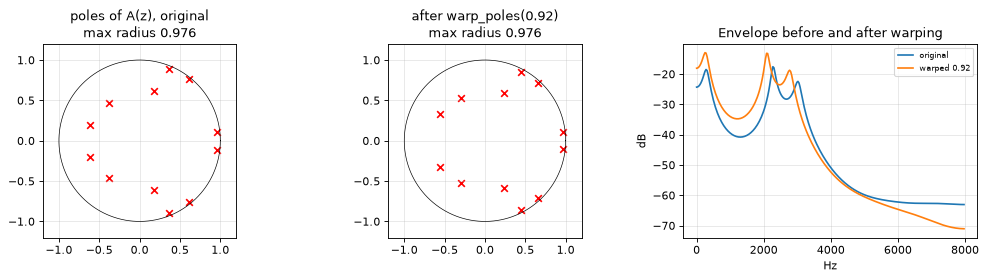

pole frequencies before (Hz): [296, 2279, 3030, 3285, 5741, 7208]
pole frequencies after  (Hz): [272, 2096, 2788, 3022, 5281, 6632]


In [7]:
a_w = lpc.warp_poles(a, 0.92)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
th = np.linspace(0, 2 * np.pi, 400)
for ax_, aa, ttl in ((axs[0], a, "poles of A(z), original"), (axs[1], a_w, "after warp_poles(0.92)")):
    z = np.roots(aa)
    ax_.plot(np.cos(th), np.sin(th), "k", lw=0.6); ax_.scatter(z.real, z.imag, c="r", marker="x")
    ax_.set_aspect("equal"); ax_.set_title(ttl + f"\nmax radius {np.abs(z).max():.3f}"); ax_.set_xlim(-1.2, 1.2); ax_.set_ylim(-1.2, 1.2)
_, env0 = lpc.lpc_envelope(a, g, 512); _, env1 = lpc.lpc_envelope(a_w, g, 512)
axs[2].plot(w, env0, label="original"); axs[2].plot(w, env1, label="warped 0.92")
axs[2].set_xlabel("Hz"); axs[2].set_ylabel("dB"); axs[2].legend(fontsize=7); axs[2].set_title("Envelope before and after warping")
plt.tight_layout(); plt.show()
fm = lambda aa: sorted(int(round(np.angle(z) * FS / (2 * np.pi))) for z in np.roots(aa) if z.imag > 0)
print("pole frequencies before (Hz):", fm(a))
print("pole frequencies after  (Hz):", fm(a_w))

**Choice of order.** Rule of thumb: about `fs/1000 + 2` poles, i.e. 18 at 16 kHz (two poles per formant, roughly one formant per kHz, plus two for the spectral tilt). Too low and formants merge; too high and the envelope starts following individual harmonics (and the cost goes up). The project uses 12, below the rule of thumb: it captures the main formants, and in the order sweep of the Module B validation notebook (B9) going from 12 to 14 improves the mean LSD by only about 0.2 dB.

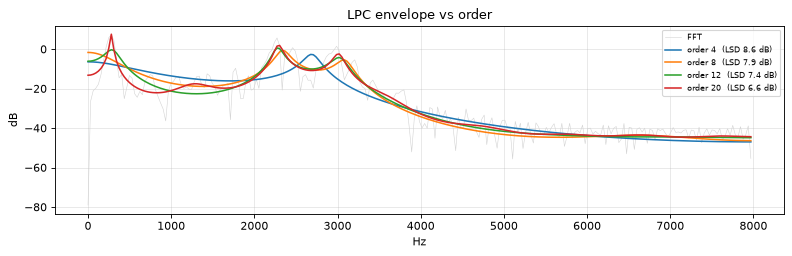

lpc_all: (256, 13) (256,)


In [8]:
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.plot(w, spec, lw=0.5, color="lightgray", label="FFT")
for p_ in (4, 8, 12, 20):
    ap, _ = lpc.lpc_frame(fr, p_)
    _, ev = lpc.lpc_envelope(ap, 1.0, 512)
    ax.plot(w, ev + (spec.mean() - ev.mean()), lw=1.4, label=f"order {p_}  (LSD {lpc.envelope_lsd(fr, p_):.1f} dB)")
ax.set_xlabel("Hz"); ax.set_ylabel("dB"); ax.legend(fontsize=7); ax.set_title("LPC envelope vs order")
plt.tight_layout(); plt.show()

A, G = lpc.lpc_all(frames, order=12)
print("lpc_all:", A.shape, G.shape)

## 5. Source: pitch contour and excitation (Module C)

Now the part that turns a whisper into voiced speech: a synthetic source.

**Pitch contour (`build_f0`).** For vowel-like frames only, f0 is built per phrase (a phrase ends after 0.5 s of silence) from:

    f0 = base_f0 * (1 - decl * position_in_phrase) * (1 + stress * energy_deviation) * (1 + small jitter)

- **declination**: pitch drifts down by 12 percent across a phrase (`position_in_phrase` goes from 0 to 1), as in natural speech
- **stress**: louder frames than the phrase average get a higher pitch (stress 0.25; `energy_deviation` is log RMS minus its phrase mean, clipped to +-1)
- **jitter**: tiny random variation (0.5 percent) so the voice is not mechanically perfect
- the result is median and moving-average smoothed and clipped to 70 to 400 Hz; f0 is 0 where the frame is not vowel-like.

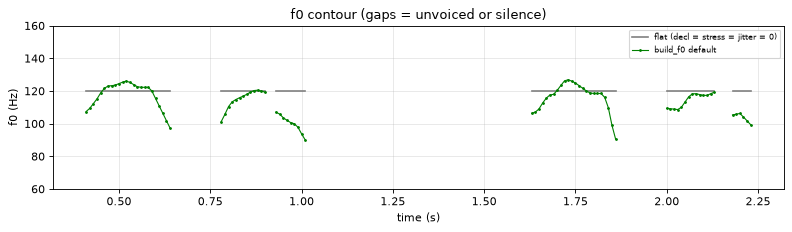

voiced frames: 90  f0 range 90 to 127 Hz, mean 114 Hz


In [9]:
f0 = pitch.build_f0(labels, energy, base_f0=120)
f0_flat = pitch.build_f0(labels, energy, base_f0=120, decl=0.0, stress=0.0, jitter=0.0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(tf, np.where(f0_flat > 0, f0_flat, np.nan), "gray", lw=1.5, label="flat (decl = stress = jitter = 0)")
ax.plot(tf, np.where(f0 > 0, f0, np.nan), "g.-", lw=1, ms=3, label="build_f0 default")
ax.set_xlabel("time (s)"); ax.set_ylabel("f0 (Hz)"); ax.set_ylim(60, 160); ax.legend(fontsize=7); ax.set_title("f0 contour (gaps = unvoiced or silence)")
plt.tight_layout(); plt.show()
v = f0[f0 > 0]
print(f"voiced frames: {len(v)}  f0 range {v.min():.0f} to {v.max():.0f} Hz, mean {v.mean():.0f} Hz" if len(v) else "no voiced frames in this clip")

**Pulse shape.** The simplest source is an **impulse train** (`impulse_train`): one sample of 1 every `T0 = fs/f0` samples. Its spectrum is flat: all harmonics have equal strength, which gives a harsh, buzzy, robotic sound.

The real glottis does not produce impulses; it produces a smooth **flow** pulse. The **Rosenberg pulse** (`rosenberg_pulse`) models one cycle: a raised-cosine opening phase (40 percent of the period), a cosine closing phase (16 percent), then closed (flat zero):

    opening:  g(n) = 0.5 (1 - cos(pi n / Tp))        closing:  g(n) = cos(pi m / (2 Tn))

Its spectrum falls about 12 dB/octave above the first few harmonics, like a real voice. That is a big part of why it sounds more natural than the impulse train.

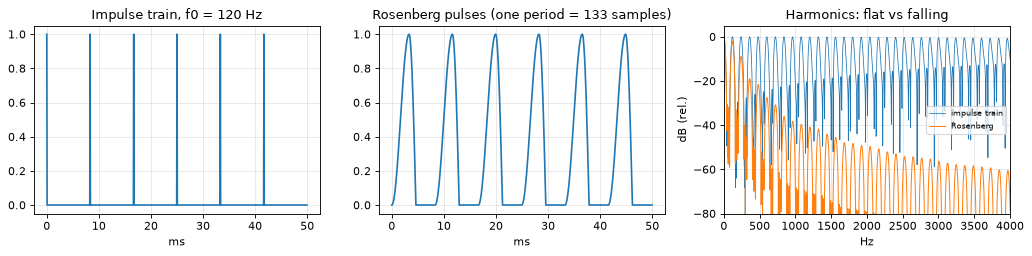

In [10]:
f_test = 120.0
T0 = FS / f_test
imp = pitch.impulse_train(f_test, 0.05)
ros_one = pitch.rosenberg_pulse(T0)
ros = np.tile(ros_one, int(0.05 * FS / len(ros_one)) + 1)[: len(imp)]
tm = np.arange(len(imp)) / FS * 1000

def harm_spec(sig_, n=8192):
    s = np.fft.rfft(sig_ * np.hanning(len(sig_)), n)
    return np.fft.rfftfreq(n, 1 / FS), 20 * np.log10(np.abs(s) / np.abs(s).max() + 1e-6)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.3))
axs[0].plot(tm, imp); axs[0].set_title("Impulse train, f0 = 120 Hz"); axs[0].set_xlabel("ms")
axs[1].plot(tm, ros); axs[1].set_title(f"Rosenberg pulses (one period = {len(ros_one)} samples)"); axs[1].set_xlabel("ms")
fi, si = harm_spec(imp); fr_, sr = harm_spec(ros)
axs[2].plot(fi, si, lw=0.7, label="impulse train"); axs[2].plot(fr_, sr, lw=0.9, label="Rosenberg")
axs[2].set_xlim(0, 4000); axs[2].set_ylim(-80, 5); axs[2].set_xlabel("Hz"); axs[2].set_ylabel("dB (rel.)"); axs[2].legend(fontsize=7)
axs[2].set_title("Harmonics: flat vs falling")
plt.tight_layout(); plt.show()

**Full excitation (`make_excitation`).** Per hop, according to the label:

- label 2 and f0 > 0: Rosenberg pulses at the (interpolated) f0, normalised to unit RMS, mixed with **aspiration noise** (`aspiration = 0.15`: mix weights 0.85 pulses and 0.15 noise, rescaled to unit RMS, so the noise is about 3 percent of the power; the breathiness that real voices keep)
- label 1 (consonant): unit-RMS white noise, same kind of source as in a whisper
- label 0 (silence): exactly zero

Pulse phase and the tail of a pulse that crosses a hop boundary are carried between hops, so there are no clicks. This same step function is what the live path calls hop by hop.

excitation length: 40960 = n_frames * hop = 40960


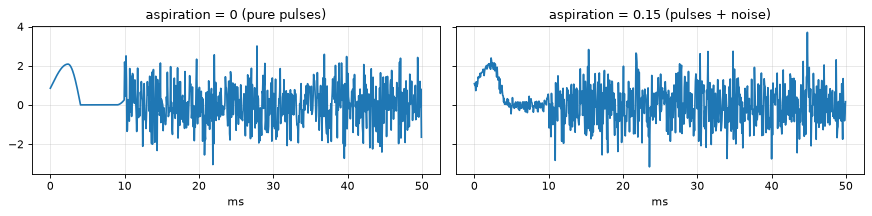

Excitation alone (before the vocal tract filter): a buzz during vowels, hiss during consonants (2.6 s)


In [11]:
e0 = pitch.make_excitation(labels, f0, aspiration=0.0)
e15 = pitch.make_excitation(labels, f0, aspiration=0.15)
print("excitation length:", len(e15), "= n_frames * hop =", len(frames) * HOP)

vi = np.flatnonzero(f0 > 0)
s0 = int(vi[len(vi) // 2]) * HOP if vi.size else len(e15) // 2
seg = slice(s0, s0 + 800)
tt = np.arange(800) / FS * 1000
fig, axs = plt.subplots(1, 2, figsize=(11, 2.8), sharey=True)
axs[0].plot(tt, e0[seg]); axs[0].set_title("aspiration = 0 (pure pulses)"); axs[0].set_xlabel("ms")
axs[1].plot(tt, e15[seg]); axs[1].set_title("aspiration = 0.15 (pulses + noise)"); axs[1].set_xlabel("ms")
plt.tight_layout(); plt.show()
play(e15 / (np.abs(e15).max() + 1e-9) * 0.5, "Excitation alone (before the vocal tract filter): a buzz during vowels, hiss during consonants", max_s=5)

## 6. Synthesis and output stage

**`synthesize`** runs the excitation of each hop through the frame's all-pole filter `G / A(z)` with `scipy.signal.lfilter`. The filter memory (`zi`) is carried from one hop to the next, so the output is continuous even though the filter coefficients change every 10 ms.

**`output_stage`** then repairs the things the model leaves out:

1. **Lip radiation** `1 - 0.98 z^-1`: sound radiating from the lips acts like a differentiator (+6 dB/octave).
2. **De-emphasis** `1 / (1 - 0.97 z^-1)`: undoes the pre-emphasis, which the LPC envelope still contains. Without it the output is too bright.
3. **DC blocker**: the Rosenberg flow pulse has a large mean, which would waste loudness on inaudible DC.
4. **Per-hop RMS match** to the input energy, with a smooth gain ramp so loudness follows the whisper's dynamics.

**`peak_protect`** finally scales the whole signal down only if a sample would clip in a wav file (above 0.99).

peak: raw synthesis 0.23, after output_stage 0.633, after peak_protect 0.633
RMS : input 0.0646, output 0.0682


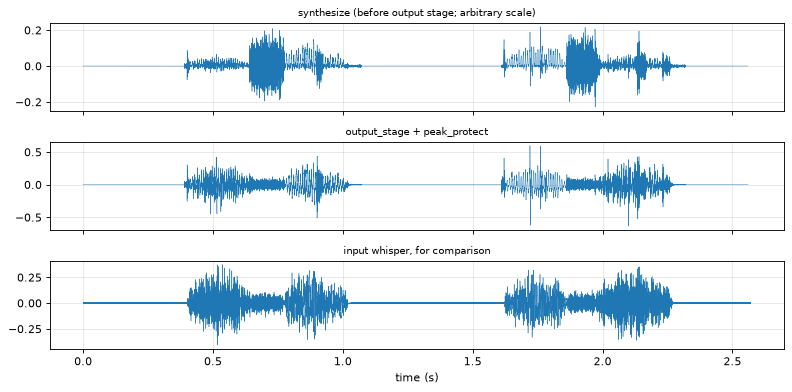

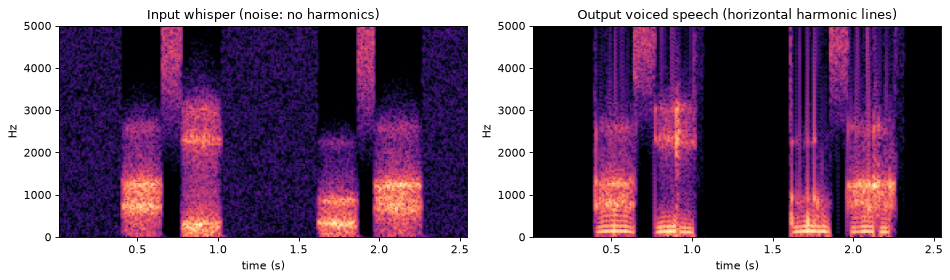

Input whisper (2.6 s)


Output voiced speech (full pipeline, variant with aspiration) (2.6 s)


In [12]:
y_raw = synth.synthesize(A, G, e15, labels, energy)
y_out = synth.output_stage(y_raw, energy)
y_final = synth.peak_protect(y_out)
n = min(len(y_final), len(x))
y_final_t = np.pad(y_final, (0, max(0, len(x) - len(y_final))))[: len(x)]
print(f"peak: raw synthesis {np.abs(y_raw).max():.2f}, after output_stage {np.abs(y_out).max():.3f}, after peak_protect {np.abs(y_final).max():.3f}")
print(f"RMS : input {np.sqrt(np.mean(x ** 2)):.4f}, output {np.sqrt(np.mean(y_final_t ** 2)):.4f}")

fig, axs = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
for ax_, s_, ttl in zip(axs, (y_raw, y_out, x), ("synthesize (before output stage; arbitrary scale)", "output_stage + peak_protect", "input whisper, for comparison")):
    s_ = y_final if ttl.startswith("output") else s_
    ax_.plot(np.arange(len(s_)) / FS, s_, lw=0.4); ax_.set_title(ttl, fontsize=9)
axs[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
vm = show_spec(axs[0], x, "Input whisper (noise: no harmonics)", fmax=5000)
show_spec(axs[1], y_final_t, "Output voiced speech (horizontal harmonic lines)", vmax=vm, fmax=5000)
plt.tight_layout(); plt.show()
play(x, "Input whisper")
play(y_final_t, "Output voiced speech (full pipeline, variant with aspiration)")

## 7. Variants and ablation

To measure what each design choice contributes, `src/synth.py` defines four cumulative variants (`VARIANTS`, rendered by `render_variant`):

| variant | what it is |
|---|---|
| `v1_robot` | flat pitch (no declination, stress or jitter), no aspiration: a monotone buzz |
| `v2_contour` | + natural pitch contour (declination, energy stress, jitter) |
| `v3_aspiration` | + aspiration noise mixed into the pulses, weight 0.15 (this is the default pipeline) |
| `v4_warp` | + formant warping 0.92 (pole angles scaled down, a slightly longer vocal tract) |

All variants share the same labels, energy and LPC; only the source or filter changes. `render_variant` takes a features dict, which we build here from the public functions already used above.

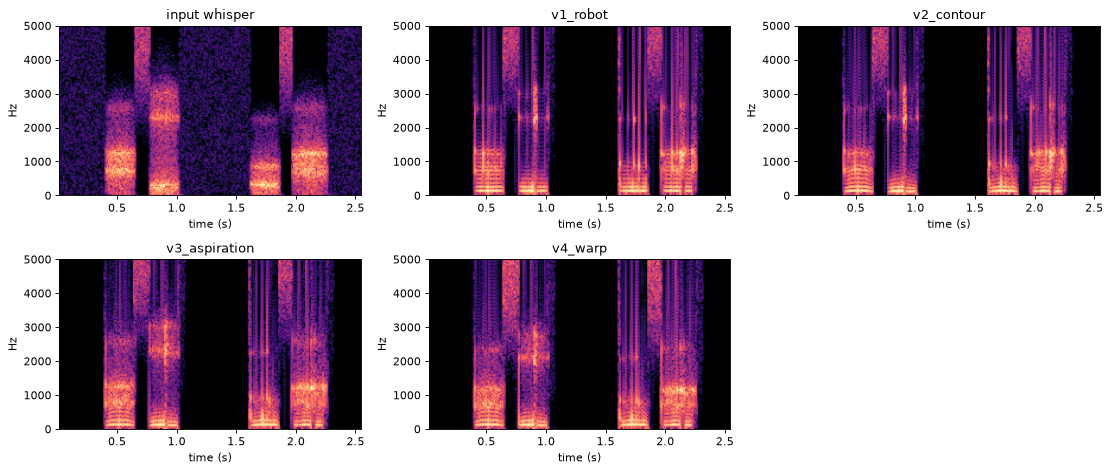

v1_robot (2.6 s)


v2_contour (2.6 s)


v3_aspiration (2.6 s)


v4_warp (2.6 s)


In [13]:
feats = dict(fs=fs, n=len(x), energy=energy, labels=np.asarray(labels), A=A, G=G)
variants = {name: synth.render_variant(feats, name) for name in synth.VARIANTS}

fig, axs = plt.subplots(2, 3, figsize=(14, 6))
vm = show_spec(axs[0, 0], x, "input whisper", fmax=5000)
for ax_, (name, yv) in zip(list(axs.ravel())[1:], variants.items()):
    show_spec(ax_, yv, name, vmax=vm, fmax=5000)
axs[1, 2].axis("off")
plt.tight_layout(); plt.show()

for name, yv in variants.items():
    play(yv, name, max_s=6)

What to listen and look for: `v1_robot` has perfectly steady harmonics and a fixed pitch. `v2_contour` has a pitch that moves and falls. `v3_aspiration` fills the gaps between harmonics with some noise, so it sounds less synthetic and more intelligible. `v4_warp` shifts the formant bands in the spectrogram slightly downward.

## 8. Live path

For the real-time demo the same chain runs **one 160-sample hop at a time** and may only use the past (it is *causal*). `process_hop_live` takes one block in, returns one block out, and carries a `state` dict (previous block for the 320-sample frame, filter memories, pitch tracker, excitation phase, output gain).

What differs from the offline path, because the future is not available:

- **Calibration**: the first 0.3 s only measures the noise floor; the output is zeros during that time.
- **ZCR threshold**: the offline percentile rule needs the whole clip; live starts at a default (0.12) and tracks the 70th percentile of the last 3 s of speech frames.
- **Labels**: the same 5-frame hangover, but no 3-frame median filter (it would need the next frame).
- **Frame alignment**: live analyses the 20 ms frame that *ends* with the current hop (previous + current block); offline, output hop `i` uses frame `i`, which *starts* at that hop. The filter and loudness target are therefore one hop (10 ms) apart between the two paths.
- **f0**: `f0_step` replaces `build_f0`: declination from running phrase time (saturating after 2 s) and stress from a running mean energy instead of the whole phrase, with one-pole smoothing instead of median plus moving-average smoothing.
- The output stage uses the current hop's RMS and a soft limiter replaces peak protect (the whole signal is not known).

**Latency.** A hop is 10 ms and the frame is 20 ms, so the algorithmic delay is about two hops (20 ms), plus the sound device buffers. The code must also finish each hop in under 10 ms to keep up (the "budget"). `process_file_live` pushes a whole file through the live code; no sound device is opened here.

live output: 41120 samples; processed 2.6 s of audio in 0.08 s
max |live - offline| = 1.046   (peak of offline output 0.633)
sample correlation live vs offline = 0.080
correlation of the RMS envelopes (loudness following the input) = 0.952
{'hops': 257, 'mean_ms': 0.314, 'p95_ms': 0.646, 'max_ms': 1.534, 'frac_over_budget': 0.0, 'algorithmic_ms': 20.0, 'device_ms': None, 'total_ms': 20.0}


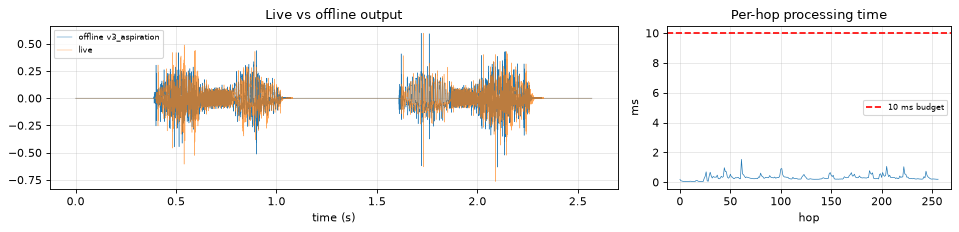

Live path output (file pushed through process_file_live) (2.6 s)


In [14]:
t0 = time.perf_counter()
y_live = live.process_file_live(x)
elapsed = time.perf_counter() - t0
state = live.process_file_live.last_state
y_off = variants["v3_aspiration"]          # offline output with the same default parameters as live

n = min(len(y_live), len(y_off))
d = y_live[:n] - y_off[:n]
corr = float(np.corrcoef(y_live[:n], y_off[:n])[0, 1])
def env_rms(s): return np.sqrt(np.mean(frames_of(s) ** 2, axis=1))
frames_of = framing.frame_signal
el, eo = env_rms(y_live), env_rms(y_off)
m = min(len(el), len(eo))
print(f"live output: {len(y_live)} samples; processed {len(x)/FS:.1f} s of audio in {elapsed:.2f} s")
print(f"max |live - offline| = {np.abs(d).max():.3f}   (peak of offline output {np.abs(y_off).max():.3f})")
print(f"sample correlation live vs offline = {corr:.3f}")
print(f"correlation of the RMS envelopes (loudness following the input) = {np.corrcoef(el[:m], eo[:m])[0, 1]:.3f}")

rep = live.latency_report(state)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rep.items()})

fig, axs = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw={"width_ratios": [2, 1]})
axs[0].plot(np.arange(n) / FS, y_off[:n], lw=0.4, label="offline v3_aspiration"); axs[0].plot(np.arange(n) / FS, y_live[:n], lw=0.4, alpha=0.7, label="live")
axs[0].set_xlabel("time (s)"); axs[0].legend(fontsize=7); axs[0].set_title("Live vs offline output")
tm_ = np.asarray(state["timings"])
axs[1].plot(tm_, lw=0.6); axs[1].axhline(live.BUDGET_MS, color="r", ls="--", label="10 ms budget")
axs[1].set_xlabel("hop"); axs[1].set_ylabel("ms"); axs[1].legend(fontsize=7); axs[1].set_title("Per-hop processing time")
plt.tight_layout(); plt.show()
play(y_live, "Live path output (file pushed through process_file_live)", max_s=6)

**Reading the numbers.** The live and offline outputs are not sample-identical, and they are not meant to be: the live path labels frames, tracks pitch and sets thresholds using only the past, so some labels differ, the f0 contour comes from a different algorithm (`f0_step` instead of `build_f0`, a few Hz apart) and the frames are one hop apart. Even a few Hz of f0 difference moves the pulse positions, so the sample correlation says little (two voices with slightly shifted pitch pulses decorrelate quickly). The parameters are the same (`v3_aspiration` uses the defaults, as does `live.default_params()`), and both paths run the same step functions for excitation, synthesis and output (`excitation_step`, `synth_step`, `output_step`); only their inputs (labels, f0, frame) differ. The informative checks are: the loudness envelopes agree (above), the spectrogram looks the same, and it sounds like the same system.

### Proof: the difference comes from the inputs, not from the synthesis code

If the claim above is right, then feeding the **offline** functions (`make_excitation`, `synthesize`, `output_stage`) with exactly the labels, f0 values and frames the live path used should reproduce the live output. The cell below pushes the clip through `process_hop_live` one hop at a time, records each decision (label, f0, and the 320-sample frame ending at the current hop), and then runs the offline chain on those recorded decisions.

* If the two outputs match to rounding error, the per-hop step functions are the same in both paths, and the live/offline difference is caused only by *causal decisions* (labels, f0, frame alignment).
* Live adds a soft limiter above 0.9; offline uses `peak_protect`. The cell prints the live peak so you can see whether the limiter was active.

In [15]:
# Live pass, recording what the live path decided at every hop
st = live.init_live_state()
n = len(x)
y_live2 = np.zeros(n, dtype=np.float32)
rec_labels, rec_f0, rec_frames = [], [], []
for i in range(0, n, HOP):
    block = np.pad(x[i:i + HOP], (0, max(0, HOP - len(x[i:i + HOP]))))
    calibrating = st["thresholds"] is None
    prev = st["prev"].copy()
    out, st = live.process_hop_live(block, st)
    rec_frames.append(np.concatenate((prev, st["prev"])))     # frame live analysed: previous + current (DC-blocked) block
    rec_labels.append(0 if calibrating else st["last_label"])
    rec_f0.append(0.0 if calibrating else st["last_f0"])
    y_live2[i:i + HOP] = out[:n - i]

rec_labels = np.array(rec_labels)
rec_f0 = np.array(rec_f0, dtype=np.float32)
rec_frames = np.array(rec_frames, dtype=np.float32)

# Offline chain, fed with the live decisions
A_r, G_r = lpc.lpc_all(rec_frames)
E_r = framing.frame_energy(rec_frames)
e_r = pitch.make_excitation(rec_labels, rec_f0)
y_hyb = synth.output_stage(synth.synthesize(A_r, G_r, e_r, rec_labels, E_r), E_r)[:n]

diff = np.abs(y_hyb - y_live2).max()
print(f"offline chain on live decisions vs live output: max |difference| = {diff:.1e}")
print(f"peak of live output = {np.abs(y_live2).max():.3f} (soft limiter starts at {live.LIMIT_KNEE})")
print(f"live output here equals process_file_live output: {np.array_equal(y_live2, y_live)}")

# How much each input differs between the two paths
lab_off = np.asarray(labels)
m = min(len(lab_off), len(rec_labels) - 1)
n_cal = int(live.default_params()["calib_s"] * FS // HOP)
agree = np.mean(rec_labels[1:m + 1][n_cal:] == lab_off[:m][n_cal:])   # live hop j analyses offline frame j-1
f0_b = pitch.build_f0(lab_off, energy)
f0_c = pitch.build_f0_causal(lab_off, energy)
v = f0_b > 0
print(f"label agreement live vs offline (aligned by one hop, after calibration): {agree:.0%}")
print(f"f0: build_f0 vs f0_step on the SAME labels: mean {np.abs(f0_b[v] - f0_c[v]).mean():.1f} Hz, max {np.abs(f0_b[v] - f0_c[v]).max():.1f} Hz apart")

offline chain on live decisions vs live output: max |difference| = 6.0e-08


peak of live output = 0.766 (soft limiter starts at 0.9)
live output here equals process_file_live output: True
label agreement live vs offline (aligned by one hop, after calibration): 91%
f0: build_f0 vs f0_step on the SAME labels: mean 5.7 Hz, max 13.2 Hz apart


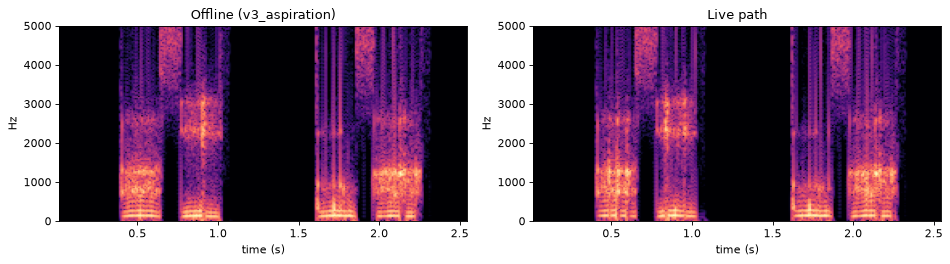

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
vm = show_spec(axs[0], y_off, "Offline (v3_aspiration)", fmax=5000)
show_spec(axs[1], y_live, "Live path", vmax=vm, fmax=5000)
plt.tight_layout(); plt.show()

## 9. Evaluation

Two objective measures, plus a listening test.

**WER (word error rate), via Whisper ASR.** The point of the project is intelligible voiced speech, so we use an automatic speech recogniser as an objective judge: transcribe the output with Whisper (base model, on CPU) and compare with the known sentence text: `WER = (substitutions + deletions + insertions) / words in reference`. Lower is better. Reference points are the raw whisper and the normally spoken recording of the same sentences. WER needs the `openai-whisper` package and real recordings, so it is produced by `run_eval.py`, not in this notebook.

**LSD (log spectral distortion).** Compare the LPC envelope of the input whisper with the envelope of the output, frame by frame (non-silent frames):

    LSD = mean over frames of  sqrt( mean over frequency of ( 20 log10|H_in| - 20 log10|H_out| )^2 )   [dB]

Lower means the output keeps the original vocal tract shape (formants), so the words should remain intelligible. A warp moves the formants on purpose, so it can raise LSD (the cost of changing the voice); on these clips the effect is small. LSD is computed below on the clip loaded above, with `evaluate.lsd_variant`, and needs no Whisper.

**Listening test.** `run_eval.py --listening` writes a blinded sheet (shuffled, coded file names) for listeners to rate clarity and naturalness, and `--aggregate-listening` collects the scores.

LSD v1_robot         13.04 dB
LSD v2_contour       13.42 dB
LSD v3_aspiration    12.08 dB
LSD v4_warp          12.19 dB
LSD live path        12.75 dB


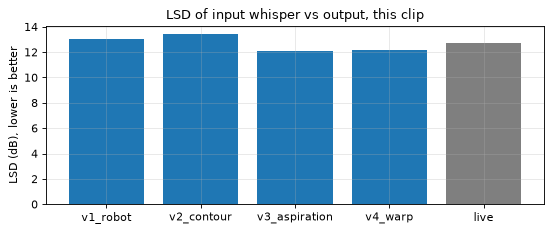

In [17]:
lsd = {name: evaluate.lsd_variant(x, yv) for name, yv in variants.items()}
lsd_live = evaluate.lsd_variant(x, y_live)
for k_, v_ in lsd.items():
    print(f"LSD {k_:15s} {v_:6.2f} dB")
print(f"LSD {'live path':15s} {lsd_live:6.2f} dB")

fig, ax = plt.subplots(figsize=(7, 3))
names = list(lsd) + ["live"]; vals = list(lsd.values()) + [lsd_live]
ax.bar(names, vals, color=["tab:blue"] * 4 + ["tab:gray"]); ax.set_ylabel("LSD (dB), lower is better"); ax.set_title("LSD of input whisper vs output, this clip")
plt.tight_layout(); plt.show()

**WER and ablation table from a full run.** If `run_eval.py` has been run on this machine, its table and figures are shown below (the cell looks in `results/` first, then in `results/dev_eval/`). The dev table comes from synthetic SAPI text-to-speech sentences that were turned into pseudo-whisper by LPC plus noise: it checks that the pipeline works, but it is **not** a result about real whisper. To produce the real table, record `data/raw/spkXX_sNN_whisper.wav` (and `_normal.wav`) and run:

    pip install openai-whisper
    python run_eval.py            # results/ablation.md, results/figures/

Showing results\dev_eval\ablation.md


SYNTHETIC DEV DATA (SAPI TTS speech, whisperised by LPC plus noise): pipeline check only, not results.

| System variant | WER | LSD (dB) | Listening clarity | Listening naturalness |
|---|---|---|---|---|
| raw_whisper | 0.328 (corpus 0.327) | 0 (reference) |  |  |
| v1_robot | 0.782 (corpus 0.796) | 10.49 |  |  |
| v2_contour | 0.736 (corpus 0.755) | 11.42 |  |  |
| v3_aspiration | 0.492 (corpus 0.510) | 6.77 |  |  |
| v4_warp | 0.750 (corpus 0.776) | 6.38 |  |  |
| normal_recording | 0.042 (corpus 0.041) |  |  |  |


fig_ablation_bar.png


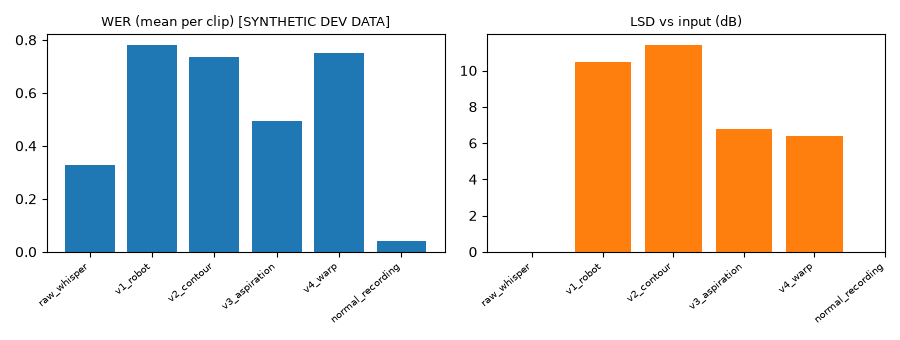

fig_envelope_overlay.png


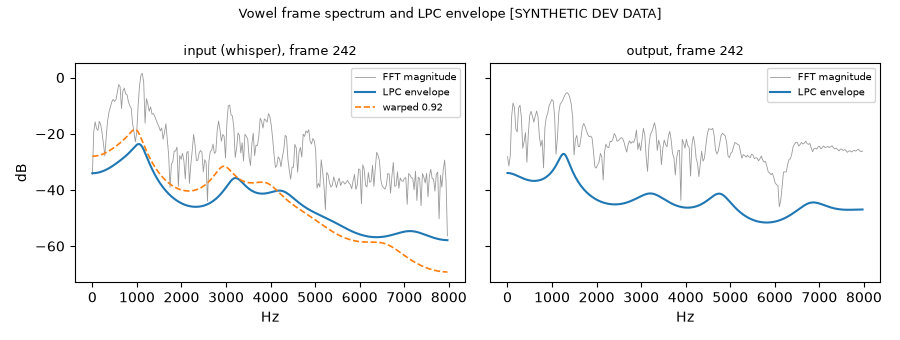

fig_f0.png


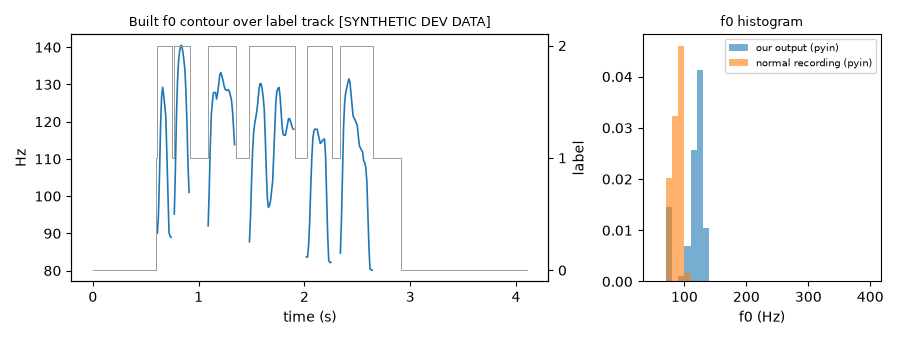

In [18]:
shown = False
for d in ("results", "results/dev_eval"):
    md_path = root / d / "ablation.md"
    if md_path.exists():
        print("Showing", md_path.relative_to(root))
        display(Markdown(md_path.read_text(encoding="utf-8")))
        figdir = root / d / "figures"
        for fn in ("fig_ablation_bar.png", "fig_envelope_overlay.png", "fig_f0.png"):
            if (figdir / fn).exists():
                print(fn); display(Image(filename=str(figdir / fn), width=700))
        shown = True
        break
if not shown:
    print("No results/ablation.md found. Run run_eval.py (needs openai-whisper and recordings) for the WER table; the LSD values above were computed directly.")

## 10. Summary and viva talking points

- **Idea**: whisper = noise source through a vocal tract filter. Keep the filter (LPC, order 12, per 20 ms frame), replace the source with a synthetic voiced one.
- **Module A** (frames, features, labels): RMS, ZCR and calibrated thresholds split silence, consonant, vowel-like. Noise floor from the first 0.3 s, hangover of 5 frames.
- **Module B** (LPC): pre-emphasis, Hamming, autocorrelation, Levinson-Durbin, gain. Envelope, residual, prediction gain and pole warping are verified against librosa and scipy references in the validation notebooks.
- **Module C** (source and synthesis): f0 contour with declination, stress and jitter; Rosenberg flow pulses plus aspiration noise (weight 0.15) for vowels, white noise for consonants, zeros for silence; filtered with state carried across hops; lip radiation, de-emphasis, DC blocker, RMS match, peak protect.
- **Ablation**: four cumulative variants (robot, contour, aspiration, warp) evaluated with Whisper WER, LSD and a blinded listening test.
- **Live**: the same excitation, synthesis and output step functions per 160-sample hop, with causal labelling and a causal pitch tracker (`f0_step`), about 20 ms algorithmic latency plus device buffers, processing time well under the 10 ms hop budget.

**Known limitations**

- The pitch contour is rule-based: it does not follow the words (no real intonation, questions, emphasis).
- Whisper spectra are different from voiced spectra (no low-frequency voice bar, different formant bandwidths), so the LPC envelope of a whisper is only an approximation of the voiced vocal tract.
- Labelling is a two-feature rule (energy and ZCR): breathy consonants and weak vowels can be misclassified. The live ZCR threshold is adaptive and starts from a default.
- Pitch is fixed per speaker by `base_f0`; it is not matched to the speaker's gender or age automatically.
- LSD only compares envelopes, and WER depends on the ASR model and on a small number of sentences; the dev table is synthetic. The listening test is small.
- Live and offline outputs are not sample-identical because the live path cannot see the future.